In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

base = "/content/drive/MyDrive/CompileGuard"

folders = [
    "dataset/safe",
    "dataset/risky",
    "results",
    "models"
]

for folder in folders:
    path = os.path.join(base, folder)
    os.makedirs(path, exist_ok=True)

print("All CompileGuard folders are ready.")

All CompileGuard folders are ready.


In [3]:
!gcc --version

gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Copyright (C) 2023 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.



In [4]:
%%writefile /content/drive/MyDrive/CompileGuard/dataset/risky/test_overflow.c
#include <stdio.h>

int main() {
    int size = 10;
    int index;

    printf("Enter index: ");
    scanf("%d", &index);

    if (index + 1 > size) {
        printf("Invalid index\n");
        return 1;
    }

    int arr[10];
    arr[index] = 100;

    printf("Value: %d\n", arr[index]);
    return 0;
}

Writing /content/drive/MyDrive/CompileGuard/dataset/risky/test_overflow.c


In [5]:
!gcc -O0 -S /content/drive/MyDrive/CompileGuard/dataset/risky/test_overflow.c -o /content/drive/MyDrive/CompileGuard/results/test_overflow_O0.s
!gcc -O2 -S /content/drive/MyDrive/CompileGuard/dataset/risky/test_overflow.c -o /content/drive/MyDrive/CompileGuard/results/test_overflow_O2.s
print("Assembly files created successfully.")

/content/drive/MyDrive/CompileGuard/dataset/risky/test_overflow.c: In function ‘main’:
/content/drive/MyDrive/CompileGuard/dataset/risky/test_overflow.c:8:5: warning: ignoring return value of ‘scanf’ declared with attribute ‘warn_unused_result’ []8;;https://gcc.gnu.org/onlinedocs/gcc/Warning-Options.html#index-Wunused-result-Wunused-result]8;;]
    8 |     scanf("%d", &index);
      |     ^~~~~~~~~~~~~~~~~~~
Assembly files created successfully.


In [6]:
print("----- O0 assembly -----")
!head -30 /content/drive/MyDrive/CompileGuard/results/test_overflow_O0.s

print("\n----- O2 assembly -----")
!head -30 /content/drive/MyDrive/CompileGuard/results/test_overflow_O2.s

----- O0 assembly -----
	.file	"test_overflow.c"
	.text
	.section	.rodata
.LC0:
	.string	"Enter index: "
.LC1:
	.string	"%d"
.LC2:
	.string	"Invalid index"
.LC3:
	.string	"Value: %d\n"
	.text
	.globl	main
	.type	main, @function
main:
.LFB0:
	.cfi_startproc
	endbr64
	pushq	%rbp
	.cfi_def_cfa_offset 16
	.cfi_offset 6, -16
	movq	%rsp, %rbp
	.cfi_def_cfa_register 6
	subq	$64, %rsp
	movq	%fs:40, %rax
	movq	%rax, -8(%rbp)
	xorl	%eax, %eax
	movl	$10, -52(%rbp)
	leaq	.LC0(%rip), %rax
	movq	%rax, %rdi

----- O2 assembly -----
	.file	"test_overflow.c"
	.text
	.section	.rodata.str1.1,"aMS",@progbits,1
.LC0:
	.string	"Enter index: "
.LC1:
	.string	"%d"
.LC2:
	.string	"Invalid index"
.LC3:
	.string	"Value: %d\n"
	.section	.text.startup,"ax",@progbits
	.p2align 4
	.globl	main
	.type	main, @function
main:
.LFB23:
	.cfi_startproc
	endbr64
	subq	$24, %rsp
	.cfi_def_cfa_offset 32
	leaq	.LC0(%rip), %rsi
	movl	$2, %edi
	movq	%fs:40, %rax
	movq	%rax, 8(%rsp)
	xorl	%eax, %eax
	call	__printf_chk@PLT
	xorl	%e

In [7]:
import os
import csv

base = "/content/drive/MyDrive/CompileGuard"
safe_dir = os.path.join(base, "dataset", "safe")
risky_dir = os.path.join(base, "dataset", "risky")
csv_path = os.path.join(base, "dataset", "labels.csv")

safe_programs = {}

safe_programs["safe_01_checked_index.c"] = r'''
#include <stdio.h>

int main() {
    int arr[10];
    int index;

    printf("Enter index: ");
    if (scanf("%d", &index) != 1) {
        return 1;
    }

    if (index < 0 || index >= 10) {
        printf("Invalid index\n");
        return 1;
    }

    arr[index] = 50;
    printf("%d\n", arr[index]);
    return 0;
}
'''

safe_programs["safe_02_fgets_input.c"] = r'''
#include <stdio.h>

int main() {
    char name[20];

    printf("Enter name: ");
    if (fgets(name, sizeof(name), stdin) != NULL) {
        printf("Hello %s", name);
    }

    return 0;
}
'''

safe_programs["safe_03_checked_division.c"] = r'''
#include <stdio.h>

int main() {
    int a, b;

    printf("Enter two numbers: ");
    if (scanf("%d %d", &a, &b) != 2) {
        return 1;
    }

    if (b == 0) {
        printf("Division by zero is not allowed\n");
        return 1;
    }

    printf("%d\n", a / b);
    return 0;
}
'''

safe_programs["safe_04_null_check.c"] = r'''
#include <stdio.h>
#include <stdlib.h>

int main() {
    int *p = malloc(sizeof(int));

    if (p == NULL) {
        printf("Memory allocation failed\n");
        return 1;
    }

    *p = 25;
    printf("%d\n", *p);

    free(p);
    return 0;
}
'''

safe_programs["safe_05_safe_copy.c"] = r'''
#include <stdio.h>
#include <string.h>

int main() {
    char source[20] = "CompileGuard";
    char destination[30];

    strncpy(destination, source, sizeof(destination) - 1);
    destination[sizeof(destination) - 1] = '\0';

    printf("%s\n", destination);
    return 0;
}
'''

safe_programs["safe_06_bounded_loop.c"] = r'''
#include <stdio.h>

int main() {
    int arr[5] = {1, 2, 3, 4, 5};

    for (int i = 0; i < 5; i++) {
        printf("%d\n", arr[i]);
    }

    return 0;
}
'''

safe_programs["safe_07_size_t_loop.c"] = r'''
#include <stdio.h>

int main() {
    int arr[8] = {10, 20, 30, 40, 50, 60, 70, 80};
    size_t n = sizeof(arr) / sizeof(arr[0]);

    for (size_t i = 0; i < n; i++) {
        printf("%d\n", arr[i]);
    }

    return 0;
}
'''

safe_programs["safe_08_checked_addition.c"] = r'''
#include <stdio.h>
#include <limits.h>

int main() {
    int a, b;

    printf("Enter two numbers: ");
    if (scanf("%d %d", &a, &b) != 2) {
        return 1;
    }

    if (a > 0 && b > INT_MAX - a) {
        printf("Addition overflow detected\n");
        return 1;
    }

    printf("%d\n", a + b);
    return 0;
}
'''

safe_programs["safe_09_file_check.c"] = r'''
#include <stdio.h>

int main() {
    FILE *fp = fopen("data.txt", "r");

    if (fp == NULL) {
        printf("File cannot be opened\n");
        return 1;
    }

    fclose(fp);
    printf("File opened successfully\n");
    return 0;
}
'''

safe_programs["safe_10_simple_math.c"] = r'''
#include <stdio.h>

int main() {
    int a = 10;
    int b = 20;

    printf("%d\n", a + b);
    return 0;
}
'''

risky_programs = {}

risky_programs["risky_01_unchecked_index.c"] = r'''
#include <stdio.h>

int main() {
    int arr[10];
    int index;

    printf("Enter index: ");
    scanf("%d", &index);

    arr[index] = 100;
    printf("%d\n", arr[index]);
    return 0;
}
'''

risky_programs["risky_02_strcpy_overflow.c"] = r'''
#include <stdio.h>
#include <string.h>

int main() {
    char small[5];
    char large[50];

    printf("Enter text: ");
    scanf("%s", large);

    strcpy(small, large);
    printf("%s\n", small);
    return 0;
}
'''

risky_programs["risky_03_signed_overflow.c"] = r'''
#include <stdio.h>

int main() {
    int size = 10;
    int index;

    printf("Enter index: ");
    scanf("%d", &index);

    if (index + 1 > size) {
        printf("Invalid index\n");
        return 1;
    }

    int arr[10];
    arr[index] = 100;
    printf("%d\n", arr[index]);
    return 0;
}
'''

risky_programs["risky_04_division_by_zero.c"] = r'''
#include <stdio.h>

int main() {
    int a, b;

    printf("Enter two numbers: ");
    scanf("%d %d", &a, &b);

    printf("%d\n", a / b);
    return 0;
}
'''

risky_programs["risky_05_null_dereference.c"] = r'''
#include <stdio.h>
#include <stdlib.h>

int main() {
    int *p = malloc(sizeof(int));

    *p = 50;
    printf("%d\n", *p);

    free(p);
    return 0;
}
'''

risky_programs["risky_06_uninitialized_variable.c"] = r'''
#include <stdio.h>

int main() {
    int x;
    int y = 10;

    printf("%d\n", x + y);
    return 0;
}
'''

risky_programs["risky_07_array_out_of_bounds.c"] = r'''
#include <stdio.h>

int main() {
    int arr[5] = {1, 2, 3, 4, 5};

    for (int i = 0; i <= 5; i++) {
        printf("%d\n", arr[i]);
    }

    return 0;
}
'''

risky_programs["risky_08_unsafe_gets.c"] = r'''
#include <stdio.h>

int main() {
    char buffer[10];

    printf("Enter text: ");
    gets(buffer);

    printf("%s\n", buffer);
    return 0;
}
'''

risky_programs["risky_09_sprintf_overflow.c"] = r'''
#include <stdio.h>

int main() {
    char buffer[10];
    char input[50];

    printf("Enter text: ");
    scanf("%s", input);

    sprintf(buffer, "%s", input);
    printf("%s\n", buffer);
    return 0;
}
'''

risky_programs["risky_10_pointer_arithmetic.c"] = r'''
#include <stdio.h>

int main() {
    int arr[5] = {1, 2, 3, 4, 5};
    int *p = arr;
    int index;

    printf("Enter index: ");
    scanf("%d", &index);

    printf("%d\n", *(p + index));
    return 0;
}
'''

for file_name, code in safe_programs.items():
    with open(os.path.join(safe_dir, file_name), "w") as f:
        f.write(code.strip() + "\n")

for file_name, code in risky_programs.items():
    with open(os.path.join(risky_dir, file_name), "w") as f:
        f.write(code.strip() + "\n")

with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["file_name", "folder", "risk_label"])

    for file_name in safe_programs:
        writer.writerow([file_name, "safe", "safe"])

    for file_name in risky_programs:
        writer.writerow([file_name, "risky", "risky"])

print("Created 20 C files and labels.csv successfully.")

Created 20 C files and labels.csv successfully.


In [8]:
import os

base = "/content/drive/MyDrive/CompileGuard/dataset"

print("Safe files:")
print(os.listdir(os.path.join(base, "safe")))

print("\nRisky files:")
print(os.listdir(os.path.join(base, "risky")))

print("\nLabel file:")
print(os.path.join(base, "labels.csv"))

Safe files:
['safe_01_checked_index.c', 'safe_02_fgets_input.c', 'safe_03_checked_division.c', 'safe_04_null_check.c', 'safe_05_safe_copy.c', 'safe_06_bounded_loop.c', 'safe_07_size_t_loop.c', 'safe_08_checked_addition.c', 'safe_09_file_check.c', 'safe_10_simple_math.c']

Risky files:
['test_overflow.c', 'risky_01_unchecked_index.c', 'risky_02_strcpy_overflow.c', 'risky_03_signed_overflow.c', 'risky_04_division_by_zero.c', 'risky_05_null_dereference.c', 'risky_06_uninitialized_variable.c', 'risky_07_array_out_of_bounds.c', 'risky_08_unsafe_gets.c', 'risky_09_sprintf_overflow.c', 'risky_10_pointer_arithmetic.c']

Label file:
/content/drive/MyDrive/CompileGuard/dataset/labels.csv


In [9]:
import pandas as pd

labels = pd.read_csv("/content/drive/MyDrive/CompileGuard/dataset/labels.csv")
labels

,file_name,folder,risk_label
0,safe_01_checked_index.c,safe,safe
1,safe_02_fgets_input.c,safe,safe
2,safe_03_checked_division.c,safe,safe
3,safe_04_null_check.c,safe,safe
4,safe_05_safe_copy.c,safe,safe
5,safe_06_bounded_loop.c,safe,safe
6,safe_07_size_t_loop.c,safe,safe
7,safe_08_checked_addition.c,safe,safe
8,safe_09_file_check.c,safe,safe
9,safe_10_simple_math.c,safe,safe


In [10]:
import os
import subprocess

base = "/content/drive/MyDrive/CompileGuard"
dataset_dir = os.path.join(base, "dataset")
results_dir = os.path.join(base, "results")

flags = ["-O0", "-O1", "-O2", "-O3"]

folders = ["safe", "risky"]
total_files = 0

for folder in folders:
    folder_path = os.path.join(dataset_dir, folder)

    for file_name in os.listdir(folder_path):
        if not file_name.endswith(".c"):
            continue

        c_file = os.path.join(folder_path, file_name)
        name_without_extension = os.path.splitext(file_name)[0]

        for flag in flags:
            flag_name = flag.replace("-", "")
            output_file = os.path.join(
                results_dir,
                f"{folder}_{name_without_extension}_{flag_name}.s"
            )

            command = [
                "gcc",
                flag,
                "-S",
                c_file,
                "-o",
                output_file
            ]

            result = subprocess.run(
                command,
                stdout=subprocess.PIPE,
                stderr=subprocess.PIPE,
                text=True
            )

            if result.returncode == 0:
                total_files += 1
            else:
                print(f"Failed: {file_name} with {flag}")
                print(result.stderr)

print("Compilation completed.")
print(f"Total assembly files created: {total_files}")

Compilation completed.
Total assembly files created: 84


In [11]:
import os

results_dir = "/content/drive/MyDrive/CompileGuard/results"

assembly_files = [f for f in os.listdir(results_dir) if f.endswith(".s")]

print(f"Total assembly files: {len(assembly_files)}")
print("\nFirst 10 files:")

for file_name in sorted(assembly_files)[:10]:
    print(file_name)

Total assembly files: 86

First 10 files:
risky_risky_01_unchecked_index_O0.s
risky_risky_01_unchecked_index_O1.s
risky_risky_01_unchecked_index_O2.s
risky_risky_01_unchecked_index_O3.s
risky_risky_02_strcpy_overflow_O0.s
risky_risky_02_strcpy_overflow_O1.s
risky_risky_02_strcpy_overflow_O2.s
risky_risky_02_strcpy_overflow_O3.s
risky_risky_03_signed_overflow_O0.s
risky_risky_03_signed_overflow_O1.s


In [12]:
import os
import subprocess
import csv

base = "/content/drive/MyDrive/CompileGuard"
dataset_dir = os.path.join(base, "dataset")
results_dir = os.path.join(base, "results")
warnings_csv = os.path.join(results_dir, "compiler_warnings.csv")

flags = ["-O0", "-O1", "-O2", "-O3"]
folders = ["safe", "risky"]

rows = []

for folder in folders:
    folder_path = os.path.join(dataset_dir, folder)

    for file_name in os.listdir(folder_path):
        if not file_name.endswith(".c"):
            continue

        c_file = os.path.join(folder_path, file_name)

        for flag in flags:
            flag_name = flag.replace("-", "")

            command = [
                "gcc",
                flag,
                "-Wall",
                "-Wextra",
                "-Wpedantic",
                "-S",
                c_file,
                "-o",
                os.devnull
            ]

            result = subprocess.run(
                command,
                stdout=subprocess.PIPE,
                stderr=subprocess.PIPE,
                text=True
            )

            warning_text = result.stderr
            warning_count = warning_text.count("warning:")

            rows.append({
                "file_name": file_name,
                "folder": folder,
                "compiler_flag": flag_name,
                "warning_count": warning_count,
                "warning_text": warning_text.strip()
            })

with open(warnings_csv, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "file_name",
            "folder",
            "compiler_flag",
            "warning_count",
            "warning_text"
        ]
    )
    writer.writeheader()
    writer.writerows(rows)

print("Compiler warning features saved.")
print(f"Total rows created: {len(rows)}")

Compiler warning features saved.
Total rows created: 84


In [13]:
import pandas as pd

warnings_df = pd.read_csv(
    "/content/drive/MyDrive/CompileGuard/results/compiler_warnings.csv"
)

warnings_df.head(10)

,file_name,folder,compiler_flag,warning_count,warning_text
0,safe_01_checked_index.c,safe,O0,0,NaN
1,safe_01_checked_index.c,safe,O1,0,NaN
2,safe_01_checked_index.c,safe,O2,0,NaN
3,safe_01_checked_index.c,safe,O3,0,NaN
4,safe_02_fgets_input.c,safe,O0,0,NaN
5,safe_02_fgets_input.c,safe,O1,0,NaN
6,safe_02_fgets_input.c,safe,O2,0,NaN
7,safe_02_fgets_input.c,safe,O3,0,NaN
8,safe_03_checked_division.c,safe,O0,0,NaN
9,safe_03_checked_division.c,safe,O1,0,NaN


In [14]:
import os
import csv

base = "/content/drive/MyDrive/CompileGuard"
results_dir = os.path.join(base, "results")
assembly_csv = os.path.join(results_dir, "assembly_features.csv")

rows = []

for file_name in sorted(os.listdir(results_dir)):
    if not file_name.endswith(".s"):
        continue

    file_path = os.path.join(results_dir, file_name)

    with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
        assembly_code = f.read()

    lines = assembly_code.splitlines()

    instruction_count = 0
    branch_count = 0
    call_count = 0
    memory_count = 0

    for line in lines:
        line = line.strip()

        if not line or line.startswith(".") or line.endswith(":"):
            continue

        instruction_count += 1

        if line.startswith("j") or "jmp" in line:
            branch_count += 1

        if "call" in line:
            call_count += 1

        if "mov" in line or "lea" in line:
            memory_count += 1

    parts = file_name.replace(".s", "").split("_")

    folder = parts[0]
    original_file = "_".join(parts[1:-1]) + ".c"
    compiler_flag = parts[-1].replace("O", "O")

    rows.append({
        "assembly_file": file_name,
        "file_name": original_file,
        "folder": folder,
        "compiler_flag": compiler_flag,
        "assembly_lines": len(lines),
        "instruction_count": instruction_count,
        "branch_count": branch_count,
        "call_count": call_count,
        "memory_count": memory_count
    })

with open(assembly_csv, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "assembly_file",
            "file_name",
            "folder",
            "compiler_flag",
            "assembly_lines",
            "instruction_count",
            "branch_count",
            "call_count",
            "memory_count"
        ]
    )
    writer.writeheader()
    writer.writerows(rows)

print("Assembly features saved.")
print(f"Total rows created: {len(rows)}")

Assembly features saved.
Total rows created: 86


In [15]:
import pandas as pd

assembly_df = pd.read_csv(
    "/content/drive/MyDrive/CompileGuard/results/assembly_features.csv"
)

assembly_df.head(10)

,assembly_file,file_name,folder,compiler_flag,assembly_lines,instruction_count,branch_count,call_count,memory_count
0,risky_risky_01_unchecked_index_O0.s,risky_01_unchecked_index.c,risky,O0,76,35,1,4,22
1,risky_risky_01_unchecked_index_O1.s,risky_01_unchecked_index.c,risky,O1,65,24,1,4,13
2,risky_risky_01_unchecked_index_O2.s,risky_01_unchecked_index.c,risky,O2,66,24,1,4,10
3,risky_risky_01_unchecked_index_O3.s,risky_01_unchecked_index.c,risky,O3,66,24,1,4,10
4,risky_risky_02_strcpy_overflow_O0.s,risky_02_strcpy_overflow.c,risky,O0,71,32,1,5,20
5,risky_risky_02_strcpy_overflow_O1.s,risky_02_strcpy_overflow.c,risky,O1,76,31,1,5,15
6,risky_risky_02_strcpy_overflow_O2.s,risky_02_strcpy_overflow.c,risky,O2,71,28,1,5,12
7,risky_risky_02_strcpy_overflow_O3.s,risky_02_strcpy_overflow.c,risky,O3,71,28,1,5,12
8,risky_risky_03_signed_overflow_O0.s,risky_03_signed_overflow.c,risky,O0,89,44,3,5,27
9,risky_risky_03_signed_overflow_O1.s,risky_03_signed_overflow.c,risky,O1,75,30,3,5,15


In [16]:
import pandas as pd
import os

base = "/content/drive/MyDrive/CompileGuard"

labels_path = os.path.join(base, "dataset", "labels.csv")
warnings_path = os.path.join(base, "results", "compiler_warnings.csv")
assembly_path = os.path.join(base, "results", "assembly_features.csv")
final_path = os.path.join(base, "results", "final_ml_dataset.csv")

labels_df = pd.read_csv(labels_path)
warnings_df = pd.read_csv(warnings_path)
assembly_df = pd.read_csv(assembly_path)

warnings_df = warnings_df[
    ["file_name", "compiler_flag", "warning_count"]
]

assembly_df = assembly_df[
    [
        "file_name",
        "compiler_flag",
        "assembly_lines",
        "instruction_count",
        "branch_count",
        "call_count",
        "memory_count"
    ]
]

final_df = labels_df.merge(
    warnings_df,
    on=["file_name"],
    how="inner"
)

final_df = final_df.merge(
    assembly_df,
    on=["file_name", "compiler_flag"],
    how="inner"
)

final_df.to_csv(final_path, index=False)

print("Final ML dataset created successfully.")
print(f"Total rows: {len(final_df)}")
final_df.head()

Final ML dataset created successfully.
Total rows: 80


,file_name,folder,risk_label,compiler_flag,warning_count,assembly_lines,instruction_count,branch_count,call_count,memory_count
0,safe_01_checked_index.c,safe,safe,O0,0,97,50,6,5,28
1,safe_01_checked_index.c,safe,safe,O1,0,84,36,4,5,17
2,safe_01_checked_index.c,safe,safe,O2,0,81,33,5,5,12
3,safe_01_checked_index.c,safe,safe,O3,0,81,33,5,5,12
4,safe_02_fgets_input.c,safe,safe,O0,0,71,31,2,4,18


In [17]:
import pandas as pd

final_df = pd.read_csv(
    "/content/drive/MyDrive/CompileGuard/results/final_ml_dataset.csv"
)

print(final_df.shape)
final_df

(80, 10)


,file_name,folder,risk_label,compiler_flag,warning_count,assembly_lines,instruction_count,branch_count,call_count,memory_count
0,safe_01_checked_index.c,safe,safe,O0,0,97,50,6,5,28
1,safe_01_checked_index.c,safe,safe,O1,0,84,36,4,5,17
2,safe_01_checked_index.c,safe,safe,O2,0,81,33,5,5,12
3,safe_01_checked_index.c,safe,safe,O3,0,81,33,5,5,12
4,safe_02_fgets_input.c,safe,safe,O0,0,71,31,2,4,18
...,...,...,...,...,...,...,...,...,...,...
75,risky_09_sprintf_overflow.c,risky,risky,O3,2,86,37,1,5,16
76,risky_10_pointer_arithmetic.c,risky,risky,O0,0,83,42,1,4,29
77,risky_10_pointer_arithmetic.c,risky,risky,O1,1,71,30,1,4,19
78,risky_10_pointer_arithmetic.c,risky,risky,O2,1,77,28,1,4,14


In [18]:
import pandas as pd

dataset_path = "/content/drive/MyDrive/CompileGuard/results/final_ml_dataset.csv"
encoded_path = "/content/drive/MyDrive/CompileGuard/results/encoded_ml_dataset.csv"

df = pd.read_csv(dataset_path)

df["risk_label"] = df["risk_label"].map({
    "safe": 0,
    "risky": 1
})

df["compiler_flag"] = df["compiler_flag"].map({
    "O0": 0,
    "O1": 1,
    "O2": 2,
    "O3": 3
})

df.to_csv(encoded_path, index=False)

print("Text values converted to numbers.")
print(df["risk_label"].value_counts())
print(df["compiler_flag"].value_counts())

Text values converted to numbers.
risk_label
0    40
1    40
Name: count, dtype: int64
compiler_flag
0    20
1    20
2    20
3    20
Name: count, dtype: int64


In [19]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

dataset_path = "/content/drive/MyDrive/CompileGuard/results/encoded_ml_dataset.csv"
model_path = "/content/drive/MyDrive/CompileGuard/models/compileguard_model.pkl"

df = pd.read_csv(dataset_path)

feature_columns = [
    "compiler_flag",
    "warning_count",
    "assembly_lines",
    "instruction_count",
    "branch_count",
    "call_count",
    "memory_count"
]

X = df[feature_columns]
y = df["risk_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Model training completed.")
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-score: {f1:.2f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model training completed.
Accuracy: 0.75
Precision: 0.83
Recall: 0.62
F1-score: 0.71

Confusion Matrix:
[[7 1]
 [3 5]]

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.88      0.78         8
           1       0.83      0.62      0.71         8

    accuracy                           0.75        16
   macro avg       0.77      0.75      0.75        16
weighted avg       0.77      0.75      0.75        16



In [20]:
import joblib

model_path = "/content/drive/MyDrive/CompileGuard/models/compileguard_model.pkl"

joblib.dump(model, model_path)

print("Model saved successfully at:")
print(model_path)

Model saved successfully at:
/content/drive/MyDrive/CompileGuard/models/compileguard_model.pkl


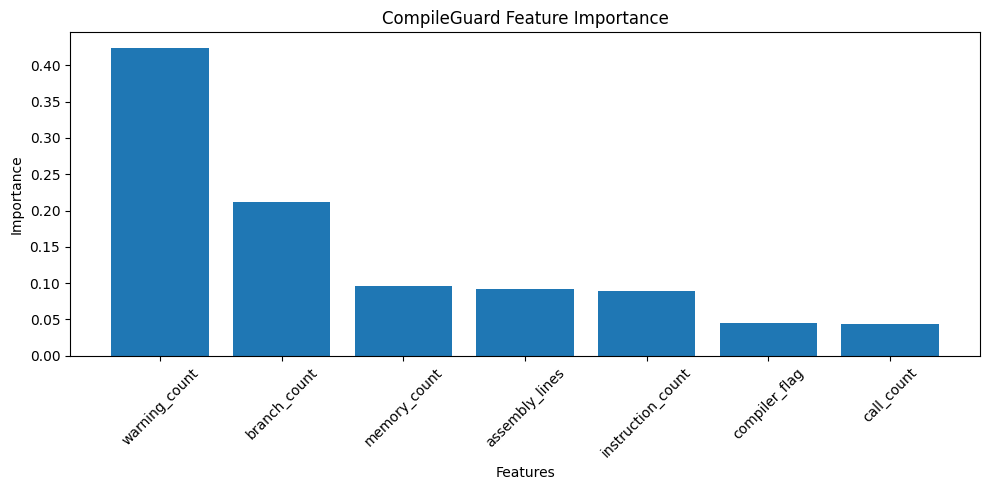

,Feature,Importance
1,warning_count,0.424184
4,branch_count,0.211232
6,memory_count,0.095558
2,assembly_lines,0.091390
3,instruction_count,0.089032
0,compiler_flag,0.044577
5,call_count,0.044028


In [21]:
import matplotlib.pyplot as plt
import pandas as pd

feature_columns = [
    "compiler_flag",
    "warning_count",
    "assembly_lines",
    "instruction_count",
    "branch_count",
    "call_count",
    "memory_count"
]

importance = model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(importance_df["Feature"], importance_df["Importance"])
plt.title("CompileGuard Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    "/content/drive/MyDrive/CompileGuard/results/feature_importance.png",
    dpi=300
)
plt.show()

importance_df

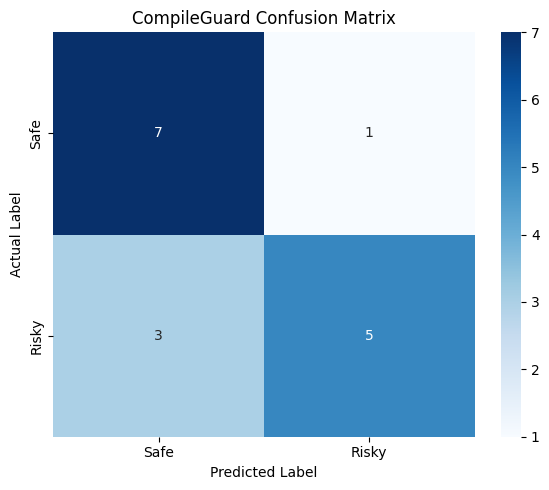

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Safe", "Risky"],
    yticklabels=["Safe", "Risky"]
)

plt.title("CompileGuard Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig(
    "/content/drive/MyDrive/CompileGuard/results/confusion_matrix.png",
    dpi=300
)
plt.show()

In [23]:
%%writefile /content/drive/MyDrive/CompileGuard/new_test_file.c
#include <stdio.h>
#include <string.h>

int main() {
    char small_buffer[8];
    char user_input[100];
    int index;

    printf("Enter text: ");
    scanf("%s", user_input);

    printf("Enter index: ");
    scanf("%d", &index);

    strcpy(small_buffer, user_input);

    if (index + 1 > 8) {
        printf("Invalid index\n");
        return 1;
    }

    int arr[8];
    arr[index] = 10;

    printf("%s %d\n", small_buffer, arr[index]);
    return 0;
}

Writing /content/drive/MyDrive/CompileGuard/new_test_file.c


In [24]:
import os
import subprocess
import joblib
import pandas as pd

base = "/content/drive/MyDrive/CompileGuard"
new_c_file = os.path.join(base, "new_test_file.c")
temp_dir = os.path.join(base, "results")
model_path = os.path.join(base, "models", "compileguard_model.pkl")

flags = ["-O0", "-O1", "-O2", "-O3"]

model = joblib.load(model_path)

all_predictions = []

for flag in flags:
    flag_name = flag.replace("-", "")
    assembly_file = os.path.join(temp_dir, f"new_test_file_{flag_name}.s")

    compile_command = [
        "gcc",
        flag,
        "-S",
        new_c_file,
        "-o",
        assembly_file
    ]

    compile_result = subprocess.run(
        compile_command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )

    warning_command = [
        "gcc",
        flag,
        "-Wall",
        "-Wextra",
        "-Wpedantic",
        "-S",
        new_c_file,
        "-o",
        os.devnull
    ]

    warning_result = subprocess.run(
        warning_command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )

    warning_count = warning_result.stderr.count("warning:")

    with open(assembly_file, "r", encoding="utf-8", errors="ignore") as f:
        assembly_code = f.read()

    lines = assembly_code.splitlines()

    instruction_count = 0
    branch_count = 0
    call_count = 0
    memory_count = 0

    for line in lines:
        line = line.strip()

        if not line or line.startswith(".") or line.endswith(":"):
            continue

        instruction_count += 1

        if line.startswith("j") or "jmp" in line:
            branch_count += 1

        if "call" in line:
            call_count += 1

        if "mov" in line or "lea" in line:
            memory_count += 1

    features = pd.DataFrame([{
        "compiler_flag": {"O0": 0, "O1": 1, "O2": 2, "O3": 3}[flag_name],
        "warning_count": warning_count,
        "assembly_lines": len(lines),
        "instruction_count": instruction_count,
        "branch_count": branch_count,
        "call_count": call_count,
        "memory_count": memory_count
    }])

    prediction = model.predict(features)[0]
    probability = model.predict_proba(features)[0]

    risk = "Risky" if prediction == 1 else "Safe"
    confidence = probability[prediction] * 100

    all_predictions.append({
        "Compiler Flag": flag,
        "Prediction": risk,
        "Confidence": round(confidence, 2),
        "Warnings": warning_count,
        "Assembly Lines": len(lines),
        "Instructions": instruction_count,
        "Branches": branch_count,
        "Calls": call_count,
        "Memory Operations": memory_count
    })

results_df = pd.DataFrame(all_predictions)
results_df

,Compiler Flag,Prediction,Confidence,Warnings,Assembly Lines,Instructions,Branches,Calls,Memory Operations
0,-O0,Safe,83.0,0,108,59,3,8,39
1,-O1,Risky,59.0,2,98,46,3,8,26
2,-O2,Risky,66.0,2,99,46,3,8,21
3,-O3,Risky,66.0,2,99,46,3,8,21


In [25]:
import os
from datetime import datetime

report_path = "/content/drive/MyDrive/CompileGuard/results/security_report.txt"

risky_count = (results_df["Prediction"] == "Risky").sum()
total_count = len(results_df)

if risky_count == total_count:
    overall_risk = "HIGH RISK"
elif risky_count > 0:
    overall_risk = "MEDIUM RISK"
else:
    overall_risk = "LOW RISK"

report = []
report.append("=========================================")
report.append("        COMPILEGUARD SECURITY REPORT")
report.append("=========================================")
report.append(f"Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
report.append(f"File analyzed: new_test_file.c")
report.append(f"Compiler used: GCC")
report.append(f"Optimization levels tested: -O0, -O1, -O2, -O3")
report.append("")
report.append(f"Overall predicted risk: {overall_risk}")
report.append(f"Risky predictions: {risky_count} out of {total_count}")
report.append("")
report.append("Detailed compiler-level analysis:")
report.append(results_df.to_string(index=False))
report.append("")
report.append("Detected security concerns:")
report.append("- Unsafe use of strcpy() may cause buffer overflow")
report.append("- Array index is not properly validated")
report.append("- index + 1 may cause signed integer overflow")
report.append("- User input is accepted without sufficient validation")
report.append("")
report.append("Recommendations:")
report.append("- Replace strcpy() with strncpy() or safer bounded copying")
report.append("- Validate index using: index >= 0 && index < array_size")
report.append("- Avoid signed integer overflow in index calculations")
report.append("- Use compiler warnings during development: -Wall -Wextra -Wpedantic")
report.append("- Test with sanitizers: -fsanitize=address,undefined")
report.append("")
report.append("=========================================")
report.append("              END OF REPORT")
report.append("=========================================")

with open(report_path, "w", encoding="utf-8") as f:
    f.write("\n".join(report))

print("\n".join(report))
print("\nReport saved at:")
print(report_path)

        COMPILEGUARD SECURITY REPORT
Date: 2026-10-26 10:04:10
File analyzed: new_test_file.c
Compiler used: GCC
Optimization levels tested: -O0, -O1, -O2, -O3

Overall predicted risk: MEDIUM RISK
Risky predictions: 3 out of 4

Detailed compiler-level analysis:
Compiler Flag Prediction  Confidence  Warnings  Assembly Lines  Instructions  Branches  Calls  Memory Operations
          -O0       Safe        83.0         0             108            59         3      8                 39
          -O1      Risky        59.0         2              98            46         3      8                 26
          -O2      Risky        66.0         2              99            46         3      8                 21
          -O3      Risky        66.0         2              99            46         3      8                 21

Detected security concerns:
- Unsafe use of strcpy() may cause buffer overflow
- Array index is not properly validated
- index + 1 may cause signed integer overflow
- User 

In [26]:
%%writefile /content/drive/MyDrive/CompileGuard/safe_test_file.c
#include <stdio.h>
#include <string.h>

int main() {
    char small_buffer[8];
    char user_input[100];
    int index;

    printf("Enter text: ");
    if (scanf("%99s", user_input) != 1) {
        return 1;
    }

    printf("Enter index: ");
    if (scanf("%d", &index) != 1) {
        return 1;
    }

    if (index < 0 || index >= 8) {
        printf("Invalid index\n");
        return 1;
    }

    strncpy(small_buffer, user_input, sizeof(small_buffer) - 1);
    small_buffer[sizeof(small_buffer) - 1] = '\0';

    int arr[8];
    arr[index] = 10;

    printf("%s %d\n", small_buffer, arr[index]);
    return 0;
}

Writing /content/drive/MyDrive/CompileGuard/safe_test_file.c


In [27]:
import os
import subprocess
import joblib
import pandas as pd

base = "/content/drive/MyDrive/CompileGuard"
safe_c_file = os.path.join(base, "safe_test_file.c")
model_path = os.path.join(base, "models", "compileguard_model.pkl")

model = joblib.load(model_path)

flags = ["-O0", "-O1", "-O2", "-O3"]
safe_predictions = []

for flag in flags:
    flag_name = flag.replace("-", "")
    assembly_file = os.path.join(base, "results", f"safe_test_file_{flag_name}.s")

    subprocess.run(
        ["gcc", flag, "-S", safe_c_file, "-o", assembly_file],
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )

    warning_result = subprocess.run(
        [
            "gcc", flag, "-Wall", "-Wextra", "-Wpedantic",
            "-S", safe_c_file, "-o", os.devnull
        ],
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )

    warning_count = warning_result.stderr.count("warning:")

    with open(assembly_file, "r", encoding="utf-8", errors="ignore") as f:
        lines = f.read().splitlines()

    instruction_count = 0
    branch_count = 0
    call_count = 0
    memory_count = 0

    for line in lines:
        line = line.strip()

        if not line or line.startswith(".") or line.endswith(":"):
            continue

        instruction_count += 1

        if line.startswith("j") or "jmp" in line:
            branch_count += 1

        if "call" in line:
            call_count += 1

        if "mov" in line or "lea" in line:
            memory_count += 1

    features = pd.DataFrame([{
        "compiler_flag": {"O0": 0, "O1": 1, "O2": 2, "O3": 3}[flag_name],
        "warning_count": warning_count,
        "assembly_lines": len(lines),
        "instruction_count": instruction_count,
        "branch_count": branch_count,
        "call_count": call_count,
        "memory_count": memory_count
    }])

    prediction = model.predict(features)[0]
    probability = model.predict_proba(features)[0]

    safe_predictions.append({
        "Compiler Flag": flag,
        "Prediction": "Risky" if prediction == 1 else "Safe",
        "Confidence": round(probability[prediction] * 100, 2),
        "Warnings": warning_count
    })

safe_results_df = pd.DataFrame(safe_predictions)
safe_results_df

,Compiler Flag,Prediction,Confidence,Warnings
0,-O0,Safe,88.0,0
1,-O1,Safe,93.0,0
2,-O2,Safe,97.0,0
3,-O3,Safe,97.0,0


In [28]:
import os

base = "/content/drive/MyDrive/CompileGuard"

print("C files:")
print(len(os.listdir(os.path.join(base, "dataset", "safe"))), "safe")
print(len(os.listdir(os.path.join(base, "dataset", "risky"))), "risky")

print("\nAssembly files:")
print(len([f for f in os.listdir(os.path.join(base, "results")) if f.endswith(".s")]))

print("\nModel exists:")
print(os.path.exists(os.path.join(base, "models", "compileguard_model.pkl")))

C files:
10 safe
11 risky

Assembly files:
94

Model exists:
True
